- 머신러닝 알고리즘은 모델의 구조가 어느 정도 고정되어 있음
    - 좋은 성능을 내기 위해서는 매개변수를 조정하고 훈련하는 과정을 반복
 
- 딥러닝은 구조를 직접 설계해야함
    - 좋은 성능을 내기 위해 다룰 수 있는 다양한 개념과 도구들을 이해할 필요가 있음

In [1]:
from tensorflow import keras
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

C:\ProgramData\anaconda3\envs\tensor_env\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
scaled_train = x_train / 255
scaled_train, scaled_val, y_train, y_val = train_test_split(scaled_train, y_train,
                                                            test_size = 0.2, stratify = y_train,
                                                            random_state = 26)

In [4]:
# 모델 정의 함수
def model_fn(a_layer = None):
    model = keras.Sequential()
    model.add(keras.Input(shape = (28, 28)))
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(100, activation = "relu"))

    if a_layer:
        model.add(a_layer)

    model.add(keras.layers.Dense(10, activation = "softmax"))

    return model

In [5]:
model = model_fn()

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

# 손실 곡선

- 케라스의 fit() 메서드는 History 클래스의 객체를 반환
    - History 객체 : 훈련 과정에서 계산한 지표(손실과 정확도값)가 저장되어 있음
    - 이 값을 사용하여 그래프를 그려서 훈련 성과를 확인

In [7]:
model.compile(loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [8]:
history = model.fit(scaled_train, y_train, epochs = 5)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7653 - loss: 0.6710
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8577 - loss: 0.3977
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8697 - loss: 0.3598
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8757 - loss: 0.3410
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8860 - loss: 0.3224


In [11]:
# history 객체 확인
print(history.history.keys())

dict_keys(['accuracy', 'loss'])


- 기본적으로 손실을 계산하고 compile 에서 accuracy 를 추가하여서 loss와 accuracy가 포함됨

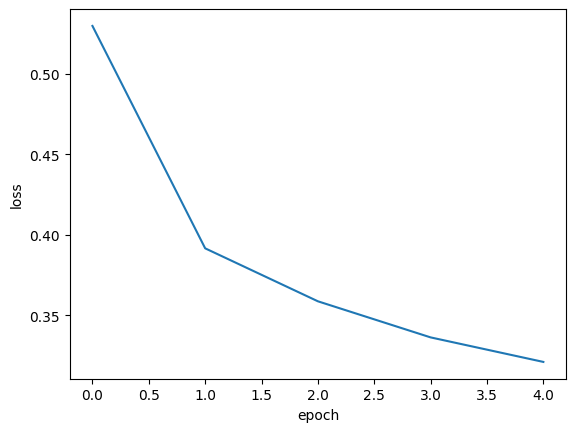

In [12]:
# 손실 곡선
plt.figure()
plt.plot(history.history["loss"])

plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

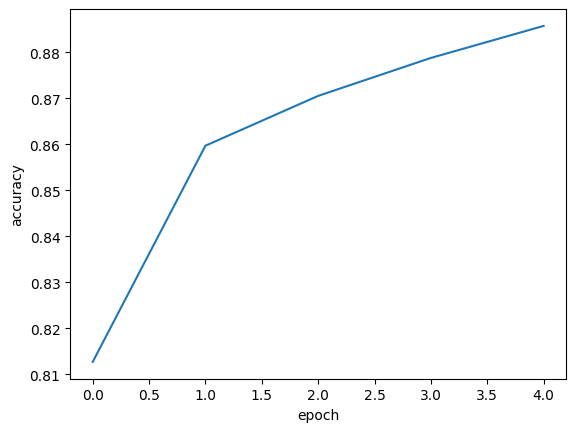

In [13]:
# 정확도 곡선
plt.figure()
plt.plot(history.history["accuracy"])

plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.show()

In [14]:
# epoch 를 20으로 늘려서 그래프 확인
model = model_fn()
model.compile(loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])
history = model.fit(scaled_train, y_train, epochs = 20)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7687 - loss: 0.6652
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8551 - loss: 0.4022
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8731 - loss: 0.3542
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8785 - loss: 0.3357
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8900 - loss: 0.3121
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8886 - loss: 0.3103
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8913 - loss: 0.3010
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9000 - loss: 0.2854
Epoch 9/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8992 - loss: 0.2804
Epoch 10/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9027 - loss: 0.2721
Epoch 11/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9055 - loss: 0.2654
Epoch 12/20
1500/1500 ━━━━━━━━

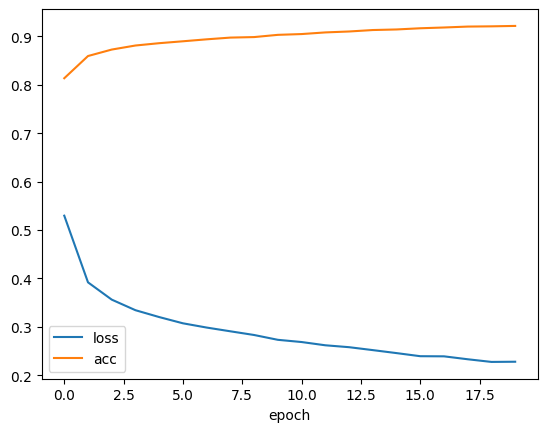

In [15]:
plt.figure()
plt.plot(history.history["loss"], label = "loss")
plt.plot(history.history["accuracy"], label = "acc")

plt.legend()
plt.xlabel("epoch")
plt.show()

# 검증 손실

- 에포크에 따른 과대적합과 과소적합을 파악하려면 검증 세트에 대한 점수도 파악해야함
- 케라스에서는 fit() 메서드에 검증 데이터를 전달할 수 있음

In [16]:
model = model_fn()
model.compile(loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [17]:
history = model.fit(scaled_train, y_train, epochs = 20, validation_data = (scaled_val, y_val))

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7616 - loss: 0.6830 - val_accuracy: 0.8428 - val_loss: 0.4401
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8532 - loss: 0.4063 - val_accuracy: 0.8709 - val_loss: 0.3616
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8691 - loss: 0.3594 - val_accuracy: 0.8709 - val_loss: 0.3615
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8796 - loss: 0.3353 - val_accuracy: 0.8391 - val_loss: 0.4502
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8841 - loss: 0.3150 - val_accuracy: 0.8847 - val_loss: 0.3396
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8884 - loss: 0.3077 - val_accuracy: 0.8812 - val_loss: 0.3470
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8944 - loss: 0.2953 - val_accuracy: 0.8832 - val_loss: 0.3553
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8946 - loss: 0.2882 - 

In [20]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


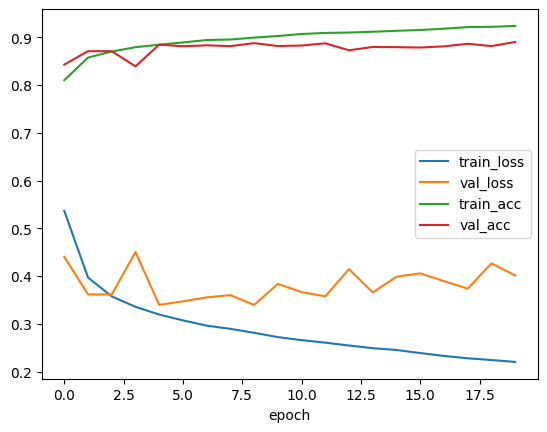

In [21]:
plt.figure()
plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

- 훈련 손실은 계속 감소하는데 검증 손실은 감소하다가 상승하여 과대적합 모델이 만들어짐
    - 검증 손실이 상승하는 시점을 가능한한 뒤로 늦출 필요가 있음

In [22]:
# Adam 옵티마이저 선택
model = model_fn()
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [23]:
history = model.fit(scaled_train, y_train, epochs = 20, validation_data = (scaled_val, y_val),
                    batch_size = 32)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7706 - loss: 0.6622 - val_accuracy: 0.8467 - val_loss: 0.4326
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8582 - loss: 0.3990 - val_accuracy: 0.8494 - val_loss: 0.4189
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8706 - loss: 0.3626 - val_accuracy: 0.8752 - val_loss: 0.3470
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8804 - loss: 0.3283 - val_accuracy: 0.8733 - val_loss: 0.3497
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8918 - loss: 0.2994 - val_accuracy: 0.8791 - val_loss: 0.3320
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8909 - loss: 0.2943 - val_accuracy: 0.8844 - val_loss: 0.3216
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8973 - loss: 0.2791 - val_accuracy: 0.8772 - val_loss: 0.3371
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9010 - loss: 0.2666 - 

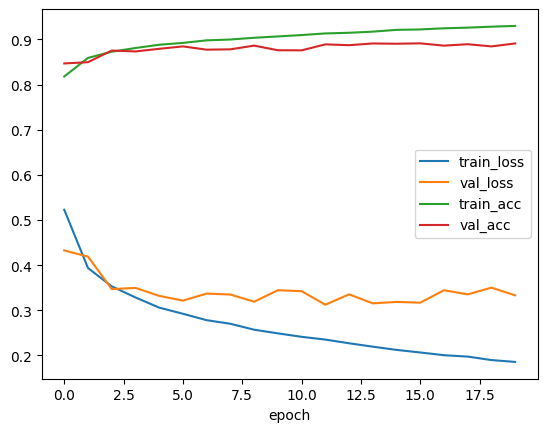

In [24]:
plt.figure()
plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

- RMSprop 을 사용할 때보다 검증 손실 그래프의 감소 추세가 길게 이어지고 있어 Adam 옵티마이저가 이 데이터셋에 잘 맞는 것으로 보임

# 드롭아웃(dropout)

<img src = "./image/DL_이미지모음/dropout.png" height = "700" width = "700">

- 훈련 과정에서 층의 일부 유닛을 랜덤하게 끄는 것으로(출력을 0으로 만드는 것으로) 과대적합을 방지
    - 특정 유닛에 과대하게 의존하는 것을 줄일 수 있음
    - 일부 유닛의 출력이 없을 수 있다는 것을 감안하여 학습하게 됨
        - 모든 입력값에 대해 충분한 주의를 기울이는 방향으로 학습
     
- 드롭아웃은 케라스에서 Dropout 클래스로 제공

- 특정 층 뒤에 드롭아웃을 두어 해당 층의 출력을 랜덤하게 0으로 만듦

- Flatten 과 마찬가지로 층처럼 사용되지만 훈련되는 모델 파라미터가 없음

In [25]:
model = model_fn(keras.layers.Dropout(0.3)) # 30%를 드롭아웃
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

- 드롭아웃 층은 입력과 출력의 크기가 같음
    - 일부 유닛의 출력을 0으로 만들지만 전체 출력 배열의 크기를 바꾸지 않음
 
- 모델 훈련이 끝난 후에 평가나 예측을 수행할 때는 드롭아웃을 적용하지 않아야 함
    - 훈련된 모든 유닛을 사용해야 올바른 예측을 수행할 수 있기 때문에
    - 케라스에서는 모델을 평가와 예측에 사용할 때에는 자동으로 드롭아웃을 적용하지 않음

In [26]:
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [27]:
history = model.fit(scaled_train, y_train, epochs = 20, validation_data = (scaled_val, y_val),
                    batch_size = 32)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7232 - loss: 0.7916 - val_accuracy: 0.8472 - val_loss: 0.4197
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8346 - loss: 0.4575 - val_accuracy: 0.8581 - val_loss: 0.3892
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8479 - loss: 0.4265 - val_accuracy: 0.8630 - val_loss: 0.3651
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8575 - loss: 0.3888 - val_accuracy: 0.8640 - val_loss: 0.3641
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8682 - loss: 0.3621 - val_accuracy: 0.8718 - val_loss: 0.3492
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8676 - loss: 0.3628 - val_accuracy: 0.8730 - val_loss: 0.3481
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8713 - loss: 0.3478 - val_accuracy: 0.8617 - val_loss: 0.3759
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8720 - loss: 0.3493 - 

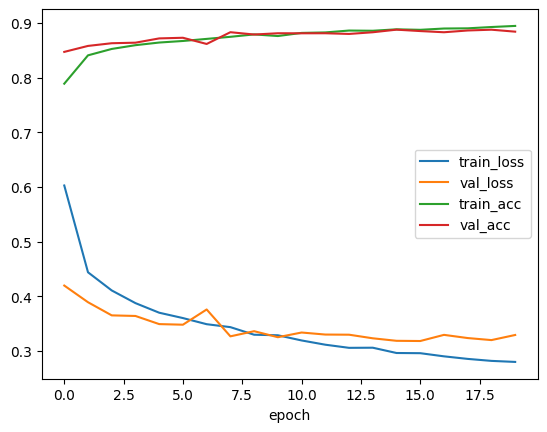

In [28]:
plt.figure()
plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xlabel("epoch")
plt.legend()
plt.show()

- 앞선 방법들에 비해 loss와 acc가 비교적 일정하게 유지됨

# 모델 저장과 복원

- 나중에 다시 사용하기 위해서 모델을 저장

- 케라스 모델은 모델의 파라미터를 저장하는 save_weights() 메서드를 제공

- 모델 구조와 모델 파라미터를 저장하는 save() 메서드도 제공

In [31]:
# 모델의 파라미터를 저장
model.save_weights("./model/model.weights.h5")

In [32]:
# 모델 구조와 모델 파라미터를 저장
model.save("./model/model-whole.keras")

## 모델 파라미터만 읽어오기

In [33]:
weights_model = model_fn(keras.layers.Dropout(0.3)) # 저장했던 모델과 정확히 같은 구조의 모델 생성

In [34]:
weights_model.load_weights("./model/model.weights.h5")

- load_weights() 메서드를 사용하려면 save_weights() 로 저장했던 모델과 정확히 같은 구조를 가져야함

- 모델 파라미터를 읽어온 모델은 evaluate() 을 사용하기 전에 compile() 을 반드시 실행해야 함

In [39]:
val_labels = np.argmax(weights_model.predict(scaled_val), axis = -1)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [40]:
print(val_labels)

[3 3 7 ... 4 6 2]


In [41]:
print(y_val)

[0 3 7 ... 4 6 2]


In [44]:
print(np.mean(val_labels == y_val))

0.8841666666666667


- 케라스의 predict() 메서드는 모델의 예측을 수행
    - 종속변수가 10개의 클래스로 이루어졌기 때문에 각 클래스에 대한 확률을 반환
 
- predict() 결과에서 가장 큰 값을 고르기 위해 argmax() 함수를 사용
    - 배열에서 가장 큰 값의 인덱스를 반환
    - 몇 번째 클래스에 대한 확률값이 가장 큰 지 반환
        - 몇 번째 클래스로 예측했는지 알 수 있음
     
- argmax() 함수의 axis = -1 은 배열의 마지막 차원을 따라서 최댓값을 고름
    - axis = 1 이면 열을 따라 각 행의 최댓값의 인덱스를 선택
    - axis = 0 이면 행을 따라 각 열의 최댓값의 인덱스를 선택

- argmax() 로 고른 인덱스와 타깃 인덱스를 비교하여 같으면 1, 다르면 0
    - 위 값의 평균을 구하면 정확도가 됨

## 모델 전체 읽어오기

In [45]:
whole_model = keras.models.load_model("./model/model-whole.keras")

In [46]:
whole_model.evaluate(scaled_val, y_val)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8815 - loss: 0.3359


[0.32927170395851135, 0.8841666579246521]

# 콜백(callback)

- 훈련 과정 중간에 어떤 작업을 수행할 수 있게 하는 객체

- fit() 메서드의 callbacks 매개변수에 리스트로 전달하여 사용

## ModelCheckpoint 콜백

- 최상의 검증 점수를 만드는 모델을 저장

In [47]:
checkpoint_cb = keras.callbacks.ModelCheckpoint("./model/best-model.keras", save_best_only = True)

In [48]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [49]:
history = model.fit(scaled_train, y_train, epochs = 20, validation_data = (scaled_val, y_val),
                    callbacks = [checkpoint_cb], batch_size = 32)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7222 - loss: 0.7925 - val_accuracy: 0.8429 - val_loss: 0.4381
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8384 - loss: 0.4507 - val_accuracy: 0.8617 - val_loss: 0.3822
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8525 - loss: 0.4072 - val_accuracy: 0.8668 - val_loss: 0.3623
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8583 - loss: 0.3869 - val_accuracy: 0.8707 - val_loss: 0.3564
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8659 - loss: 0.3654 - val_accuracy: 0.8693 - val_loss: 0.3514
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8690 - loss: 0.3559 - val_accuracy: 0.8731 - val_loss: 0.3426
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8724 - loss: 0.3449 - val_accuracy: 0.8756 - val_loss: 0.3400
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8759 - loss: 0.3323 - 

- 모델이 훈련한 후에 best-model.keras 에 최상의 val_loss 를 낸 모델이 저장됨

In [50]:
best_model = keras.models.load_model("./model/best-model.keras")

In [51]:
best_model.evaluate(scaled_val, y_val)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8866 - loss: 0.3206


[0.3112928867340088, 0.890250027179718]

- ModelCheckpoin 콜백이 가장 낮은 검증 손실값의 모델을 자동으로 저장해주어 편하지만 여전히 많은 훈련을 해야해서 불편함이 있음

## EarlyStopping 콜백

- 과대적합이 시작되기 전에(검증 손실이 상승할 때) 훈련을 미리 중지하는 것을 조기종료(early stopping)라고 부름

- 훈련 에포크 횟수를 제한하는 역할이지만 모델이 과대적합되는 것을 막아 주기 때문에 규제 방법 중 하나로 여겨지기도 함

In [5]:
early_stopping_cb = keras.callbacks.EarlyStopping(patience = 2, restore_best_weights = True)

- patience
    - 검증 점수가 향상되지 않더라도 지켜볼 에포크 횟수
    - patience 가 2라면 2번 연속 검증 점수가 향상되지 않으면 훈련 중지

- restore_best_weights
    - 가장 낮은 검증 손실을 낸 모델의 상태로 되돌림

In [6]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [7]:
history = model.fit(scaled_train, y_train, epochs = 20, validation_data = (scaled_val, y_val),
                    callbacks = [early_stopping_cb], batch_size = 32)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7353 - loss: 0.7750 - val_accuracy: 0.8359 - val_loss: 0.4382
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8405 - loss: 0.4450 - val_accuracy: 0.8566 - val_loss: 0.3904
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8555 - loss: 0.4044 - val_accuracy: 0.8553 - val_loss: 0.3889
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8577 - loss: 0.3887 - val_accuracy: 0.8736 - val_loss: 0.3473
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8629 - loss: 0.3736 - val_accuracy: 0.8730 - val_loss: 0.3473
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8716 - loss: 0.3547 - val_accuracy: 0.8794 - val_loss: 0.3361
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8696 - loss: 0.3541 - val_accuracy: 0.8586 - val_loss: 0.3727
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8754 - loss: 0.3339 - 

In [8]:
# 몇 번째 에포크에서 중지되었는지 확인
print(early_stopping_cb.stopped_epoch)

7


- 8번째 에포크까지 훈련한 후 중지됨
    - patience 가 2이기 때문에 6번째 에포크 때의 모델이 최상의 모델임

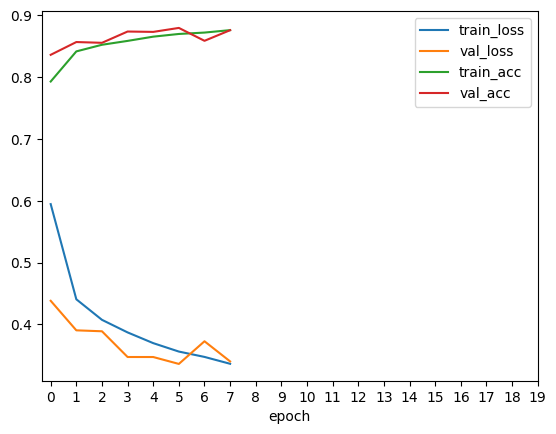

In [9]:
plt.figure()
plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xticks(ticks = range(20))
plt.xlabel("epoch")
plt.legend()
plt.show()

In [10]:
model.evaluate(scaled_val, y_val)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8764 - loss: 0.3440


[0.3360935151576996, 0.8794166445732117]

# validation_split

- 훈련 데이터를 자체적으로 훈련/검증 셋으로 나누어서 훈련/검증을 수행

In [11]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
scaled_train = x_train / 255
scaled_test =x_test / 255

In [12]:
es_cb = keras.callbacks.EarlyStopping(patience = 2, restore_best_weights = True)

In [13]:
scaled_train.shape

(60000, 28, 28)

In [14]:
model = model_fn(keras.layers.Dropout(0.3))
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [15]:
history = model.fit(scaled_train, y_train, epochs = 20, validation_split = 0.2,
                    callbacks = [es_cb], batch_size = 32)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7231 - loss: 0.7915 - val_accuracy: 0.8479 - val_loss: 0.4236
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8353 - loss: 0.4521 - val_accuracy: 0.8601 - val_loss: 0.3852
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8532 - loss: 0.4143 - val_accuracy: 0.8637 - val_loss: 0.3789
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8574 - loss: 0.3869 - val_accuracy: 0.8758 - val_loss: 0.3473
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8660 - loss: 0.3630 - val_accuracy: 0.8795 - val_loss: 0.3355
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8687 - loss: 0.3569 - val_accuracy: 0.8734 - val_loss: 0.3485
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8750 - loss: 0.3408 - val_accuracy: 0.8781 - val_loss: 0.3375


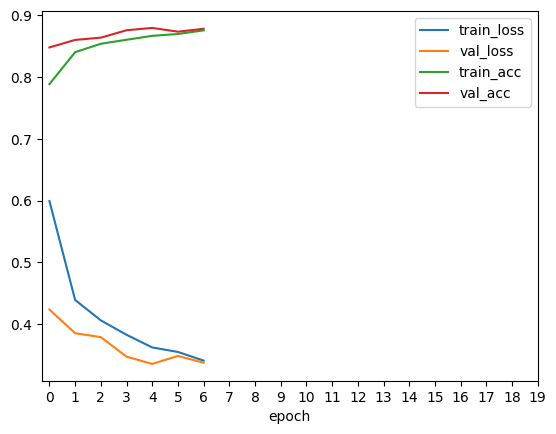

In [16]:
plt.figure()
plt.plot(history.history["loss"], label = "train_loss")
plt.plot(history.history["val_loss"], label = "val_loss")
plt.plot(history.history["accuracy"], label = "train_acc")
plt.plot(history.history["val_accuracy"], label = "val_acc")

plt.xticks(ticks = range(20))
plt.xlabel("epoch")
plt.legend()
plt.show()

In [17]:
model.evaluate(scaled_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8712 - loss: 0.3579


[0.3652249872684479, 0.8689000010490417]